<a href="https://colab.research.google.com/github/bgeethagayathri2-del/Decision-tree-vs-random-forest/blob/main/Tree_vs_forest.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Decision Tree accuracy: 0.944
Random Forest accuracy: 1.0
Decision Tree cross-val accuracy: 0.871
Random Forest cross-val accuracy: 0.972


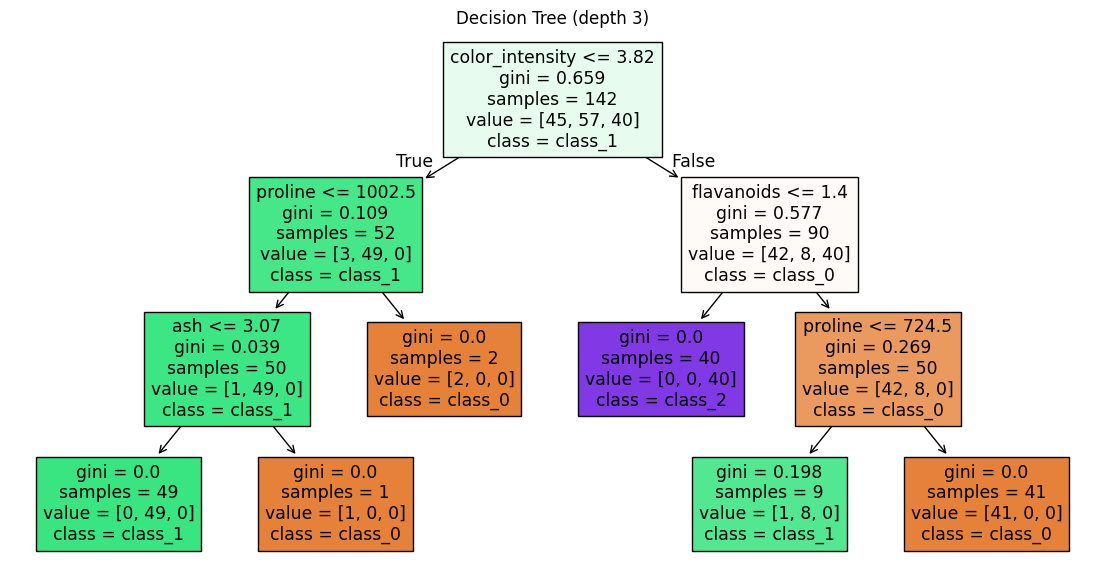

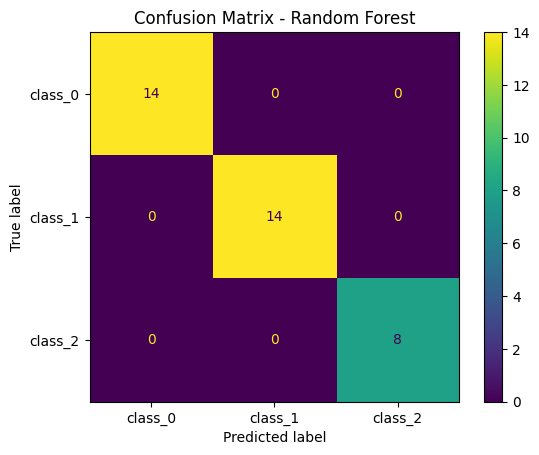

flavanoids 0.202
color_intensity 0.171
proline 0.139
alcohol 0.112
od280/od315_of_diluted_wines 0.112


In [1]:
# Decision Tree vs Random Forest on the Wine dataset
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Load data (178 wines, 3 types, 13 chemical features)
data = load_wine()
X, y = data.data, data.target

# 2. Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Train two models
dt = DecisionTreeClassifier(max_depth=3, random_state=42)
dt.fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

# 4. Test accuracy
dt_acc = accuracy_score(y_test, dt.predict(X_test))
rf_acc = accuracy_score(y_test, rf.predict(X_test))
print("Decision Tree accuracy:", round(dt_acc, 3))
print("Random Forest accuracy:", round(rf_acc, 3))

# 5. Cross-validation (a fairer test: 5 different splits)
dt_cv = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=42), X, y, cv=5).mean()
rf_cv = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42), X, y, cv=5).mean()
print("Decision Tree cross-val accuracy:", round(dt_cv, 3))
print("Random Forest cross-val accuracy:", round(rf_cv, 3))

# 6. Draw the decision tree
plt.figure(figsize=(14, 7))
plot_tree(dt, feature_names=data.feature_names,
          class_names=data.target_names, filled=True)
plt.title("Decision Tree (depth 3)")
plt.show()

# 7. Confusion matrix for Random Forest
ConfusionMatrixDisplay(
    confusion_matrix(y_test, rf.predict(X_test)),
    display_labels=data.target_names
).plot()
plt.title("Confusion Matrix - Random Forest")
plt.show()

# 8. Top features
for feature, score in sorted(zip(data.feature_names, rf.feature_importances_),
                             key=lambda x: -x[1])[:5]:
    print(feature, round(score, 3))